In [20]:
import pandas as pd
import os
import numpy as np
import pickle
from dotenv import load_dotenv

In [21]:
load_dotenv()

X_train_path = os.getenv("X_TRAIN_CSV_PATH")
y_train_path = os.getenv("Y_TRAIN_TSV_PATH")
X_test_path = os.getenv("X_TEST_CSV_PATH")
y_test_path = os.getenv("Y_TEST_TSV_PATH")
output_dir = os.getenv("OUTPUT_DIR")
random_seed = int(os.getenv("RANDOM_SEED"))

X_path = os.getenv("LABELED_DIAGNOSTIC_X_CSV_PATH")
y_path = os.getenv("LABELED_DIAGNOSTIC_Y_TSV_PATH")

# Print configuration
print(f"X_train_path: {X_train_path}")
print(f"y_train_path: {y_train_path}")
print(f"X_test_path: {X_test_path}")
print(f"y_test_path: {y_test_path}")
print(f"output_dir: {output_dir}")
print(f"random_seed: {random_seed}")
print(f"X_path: {X_path}")
print(f"y_path: {y_path}")

X_train_path: /home/mariya/Data/pallas/training/pallas.split.labeled_diagnostic.train.X.csv
y_train_path: /home/mariya/Data/pallas/training/pallas.split.labeled_diagnostic.train.y.tsv
X_test_path: /home/mariya/Data/pallas/training/pallas.split.labeled_diagnostic.test.X.csv
y_test_path: /home/mariya/Data/pallas/training/pallas.split.labeled_diagnostic.test.y.tsv
output_dir: /home/mariya/Data/pallas/training
random_seed: 42
X_path: /home/mariya/Data/pallas/nf-core-gexml-output/transpose/transposed.csv
y_path: /home/mariya/Data/pallas/nf-core-gexml-output/class/subtypes.tsv


In [22]:
# X_train = pd.read_csv(X_train_path, index_col=0)
# y_train = pd.read_csv(y_train_path, sep="\t", index_col=0)
# # Join them
# joined = X_train.join(y_train)
# # Get items containing "KMT2A" in the "class" column
# joined = joined[joined["class"].str.contains("ETV6")]
# # Separate back to X and y
# X_train = joined.drop(columns=["class"])
# y_train = joined["class"]
# # Update class col as follows: if it contains "-like", set to 0. Otherwise, set to 1.
# y_train = y_train.apply(lambda x: 0 if "-like" in x else 1)
# y_train

In [23]:
# X_test = pd.read_csv(X_test_path, index_col=0)
# y_test = pd.read_csv(y_test_path, sep="\t", index_col=0)
# y_test = y_test['class']
# joined = X_test.join(y_test)
# joined = joined[joined["class"].str.contains("ETV6")]
# X_test = joined.drop(columns=["class"])
# y_test = joined["class"]

# # Update class col as follows: if it contains "-like", set to 0. Otherwise, set to 1.
# y_test = y_test.apply(lambda x: 0 if "-like" in x else 1)

# y_test

In [24]:
X = pd.read_csv(X_path, index_col=0)
y = pd.read_csv(y_path, sep="\t", index_col=0)


In [29]:
# Join them
joined = X.join(y)
joined_selected = joined[joined["class"].str.contains("AML")]
print(joined_selected["class"].value_counts())


class
Disease,AML,KMT2A-r           107
Disease,AML,RUNX1::RUNX1T1     97
Disease,AML,CBFB::MYH11        64
Disease,AML,NPM1alt            28
Disease,AML,NUP98-r            22
Disease,AML,CEBPAalt           15
Disease,AML,DEK::NUP214         9
Disease,AML,CBFA2T3::GLIS2      8
Disease,AML,APL-PML::RARA       5
Name: count, dtype: int64


In [33]:

# Update class col as follows: if it contains "DEK::NUP214", set to 1. Otherwise, set to 0.
# joined_selected["class"] = joined_selected["class"].apply(lambda x: 1 if "DEK::NUP214" not in x else 0)
# Separate back to X and y
# X = joined.drop(columns=["class"])
# y = joined["class"]
# y
joined_selected_binary = joined_selected.copy()
joined_selected_binary["class"] = joined_selected_binary["class"].apply(lambda x: 0 if "DEK::NUP214" not in x else 1)
X = joined_selected_binary.drop(columns=["class"])
y = joined_selected_binary["class"]
y

id
SJAML001409_D2    0
SJAML001414_D3    0
SJAML001427_D2    0
SJAML001427_D3    0
SJAML001441_D3    0
                 ..
SJMLL020_D        0
SJMLL021_D        0
SJMLL022_D        0
SJPML030005_D1    0
SJPML033216_D1    0
Name: class, Length: 355, dtype: int64

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression

# ----------------------------
# Example: Gene expression data
# ----------------------------
# X = samples × genes (numpy array or dataframe)
# y = binary labels (numpy array)

# Suppose you already have X, y loaded
# X = pd.read_csv("gene_expression_matrix.csv", index_col=0)
# y = pd.read_csv("labels.csv").values.ravel()
# X = X_train
# y = y_train
gene_names = X.columns
# X = X.values

# ----------------------------
# Pipeline: preprocessing + feature selection + classifier
# ----------------------------

# # 1. Standardize (genes often have different scales)
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)

# 2. Feature selection (select top 200 genes by ANOVA F-test)
selector = SelectKBest(score_func=f_classif, k=200)
X_selected = selector.fit_transform(X, y)
selected_gene_names = gene_names[selector.get_support(indices=True)]

# 3. Logistic Regression with L1 regularization (sparse model)
log_reg = LogisticRegression(penalty='l1', solver='saga', max_iter=5000, C=1.0)

# 4. Cross-validation (since dataset is small)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(log_reg, X_selected, y, cv=skf, scoring='roc_auc')

print("Cross-validated AUC scores:", scores)
print("Mean AUC:", scores.mean())

# ----------------------------
# Train final model and extract top genes
# ----------------------------
log_reg.fit(X_selected, y)
coef = log_reg.coef_[0]


Cross-validated AUC scores: [0.97142857 0.98550725 1.         1.         1.        ]
Mean AUC: 0.9913871635610766


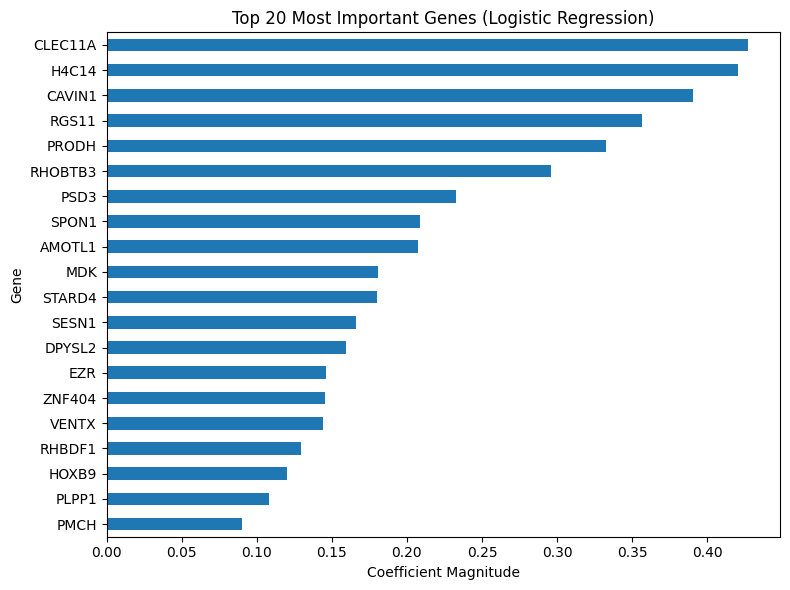

In [35]:

from gene_thesaurus import GeneThesaurus

gt = GeneThesaurus()

# Get top 20 genes by absolute weight
importance = pd.Series(np.abs(coef), index=selected_gene_names)
top_genes = importance.sort_values(ascending=False).head(20)

symbols = gt.translate_genes(top_genes.index.values,
                            source='ensembl_id',
                            target='symbol')

# Update top_genes index to symbols where available
top_genes.index = [symbols.get(gene, gene) for gene in top_genes.index]

# Plot
plt.figure(figsize=(8,6))
top_genes.sort_values().plot(kind='barh')
plt.title("Top 20 Most Important Genes (Logistic Regression)")
plt.xlabel("Coefficient Magnitude")
plt.ylabel("Gene")
plt.tight_layout()
plt.show()


In [ ]:
# Process test set the same as training
X_test = pd.read_csv(X_test_path, index_col=0)
y_test = pd.read_csv(y_test_path, sep="\t", index_col=0)
# Join them
joined = X_test.join(y_test)
# Get items containing "KMT2A" in the "class" column
joined = joined[joined["class"].str.contains("ETV6")]
# Separate back to X and y
X_test = joined.drop(columns=["class"])
y_test = joined["class"]
# Update class col as follows: if it contains "-like", set to 0. Otherwise, set to 1.
y_test = y_test.apply(lambda x: 0 if "-like" in x else 1)
print(y_test)


id
SJBALL002240      1
SJETV111          1
SJETV022015       1
ALLT-342          1
ALLT-366          1
SJBALL020653      1
SJETV045          1
ALL_761           0
SJETV021939       1
SJETV054          1
SJETV107          1
Case_190          1
Case_134          1
SJETV078          1
SJBALL020690      1
ALL_493           1
GE8322            1
SJETV096          1
SJALL016668       1
SJALL014950       1
SJALL016673       1
SJBALL020663      1
ALL_495           0
SJALL040082       1
SJCOGALL010885    1
ALL_618           1
ALL_679           0
SJALL014955       1
SJETV076          1
SJBALL020693      0
ALL_646           0
ALL_386           1
Case_180          1
SJBALL016280      1
ALL_541           1
SJBALL022035      0
GE8315            1
SJETV009          1
SJALL040123       1
SJBALL021197      0
ALL_167           1
SJALL054456       0
SJBALL020164      1
SJETV021990       1
SJETV028          1
SJETV021963       1
Case_85           0
SJETV068          1
SJETV021977       1
ALL_1163         

In [56]:

X_test_selected = selector.transform(X_test)
preds = log_reg.predict(X_test_selected)

# Show preds alongside true labels
results = pd.DataFrame({"true": y_test, "pred": preds})
print(results)

# Show accuracy score
import numpy as np
from sklearn.metrics import accuracy_score
print("Accuracy:", accuracy_score(y_test, preds))


                true  pred
id                        
SJBALL002240       1     1
SJETV111           1     1
SJETV022015        1     1
ALLT-342           1     1
ALLT-366           1     1
SJBALL020653       1     1
SJETV045           1     1
ALL_761            0     0
SJETV021939        1     1
SJETV054           1     1
SJETV107           1     1
Case_190           1     1
Case_134           1     1
SJETV078           1     1
SJBALL020690       1     1
ALL_493            1     1
GE8322             1     1
SJETV096           1     1
SJALL016668        1     1
SJALL014950        1     1
SJALL016673        1     1
SJBALL020663       1     1
ALL_495            0     0
SJALL040082        1     1
SJCOGALL010885     1     1
ALL_618            1     1
ALL_679            0     0
SJALL014955        1     1
SJETV076           1     1
SJBALL020693       0     0
ALL_646            0     0
ALL_386            1     1
Case_180           1     1
SJBALL016280       1     1
ALL_541            1     1
S